# Simple Linear Regression — Study Hours and Exam Score

This notebook repeats the complete single-feature regression pipeline with a newly generated numeric dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rng = np.random.default_rng(7)
study_hours = np.linspace(1, 20, 120)
exam_score = 35 + 3.1 * study_hours + rng.normal(0, 5, size=study_hours.size)
df = pd.DataFrame({"study_hours": study_hours, "exam_score": exam_score})
df.head()

,study_hours,exam_score
0,1.000000,38.106151
1,1.159664,40.088686
2,1.319328,37.719227
3,1.478992,35.131915
4,1.638655,37.806478


## 1. Preprocessing

encode the missing values of the data set of given 

In [2]:
print('Missing values:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()
df_clean = df[(df['study_hours'] > 0) & (df['exam_score'].between(0, 100))].copy()
print('Rows after preprocessing:', len(df_clean))
df_clean.describe()

Missing values:
 study_hours    0
exam_score     0
dtype: int64
Duplicate rows: 0
Rows after preprocessing: 118


,study_hours,exam_score
count,118.000000,118.000000
mean,10.361985,66.241308
std,5.495098,17.886377
min,1.000000,35.131915
25%,5.670168,50.782149
50%,10.340336,66.776536
75%,15.010504,80.568959
max,20.000000,97.963730


by using scatter plot we have find the relation betwwen x and y 

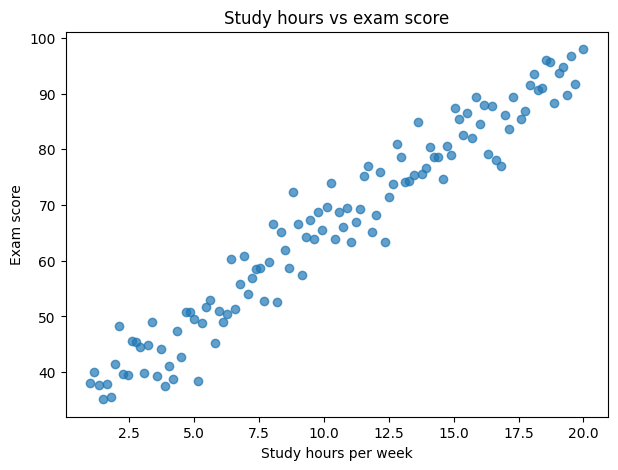

In [3]:
plt.figure(figsize=(7,5))
plt.scatter(df_clean['study_hours'], df_clean['exam_score'], alpha=0.7)
plt.xlabel('Study hours per week')
plt.ylabel('Exam score')
plt.title('Study hours vs exam score')
plt.show()

## 2. Train/test split

In [4]:
X = df_clean[['study_hours']].values
y = df_clean['exam_score'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))

Training rows: 94
Test rows: 24


## 3. Fit and predict

create fit and predict for x and y model of exam score and study hours 

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)
w = model.coef_[0]
b = model.intercept_
print(f'Learned formula: exam_score = {w:.3f} * study_hours + {b:.3f}')
y_pred = model.predict(X_test)
y_pred[:5]

Learned formula: exam_score = 3.139 * study_hours + 33.910


array([65.1165011 , 81.65634274, 39.05372033, 59.60322055, 50.08028142])

**Plain-English meaning of `w`: For this dataset, `w` is the expected change in exam score, in points, for each additional hour studied per week.

## 4. Test-set metrics

create a Test -set metrics by using r2 

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f'MAE: {mae:.2f} points')
print(f'RMSE: {rmse:.2f} points')
print(f'R²: {r2:.3f}')

MAE: 3.68 points
RMSE: 4.58 points
R²: 0.944


compare actual test score with predicted line using scatter plot. x is for study hours per week and y is for exam exam .

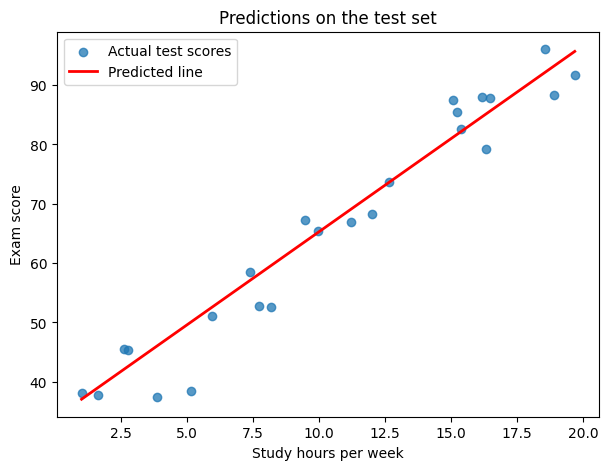

In [7]:
order = X_test.flatten().argsort()
plt.figure(figsize=(7,5))
plt.scatter(X_test, y_test, alpha=0.75, label='Actual test scores')
plt.plot(X_test.flatten()[order], y_pred[order], color='red', linewidth=2, label='Predicted line')
plt.xlabel('Study hours per week')
plt.ylabel('Exam score')
plt.title('Predictions on the test set')
plt.legend()
plt.show()